# P&ID to HAZOP scenarios: walkthrough

Stage by stage on the synthetic drawings: open a vector-PDF P&ID, read equipment, lines, valves and instruments, build the plant graph, draft the HAZOP worksheet, and score everything against the generator's ground truth.

*All drawings are synthetic. No plant drawings are used.*

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 120)

## 1. Load a drawing

30 standard drawings, 20 hard drawings


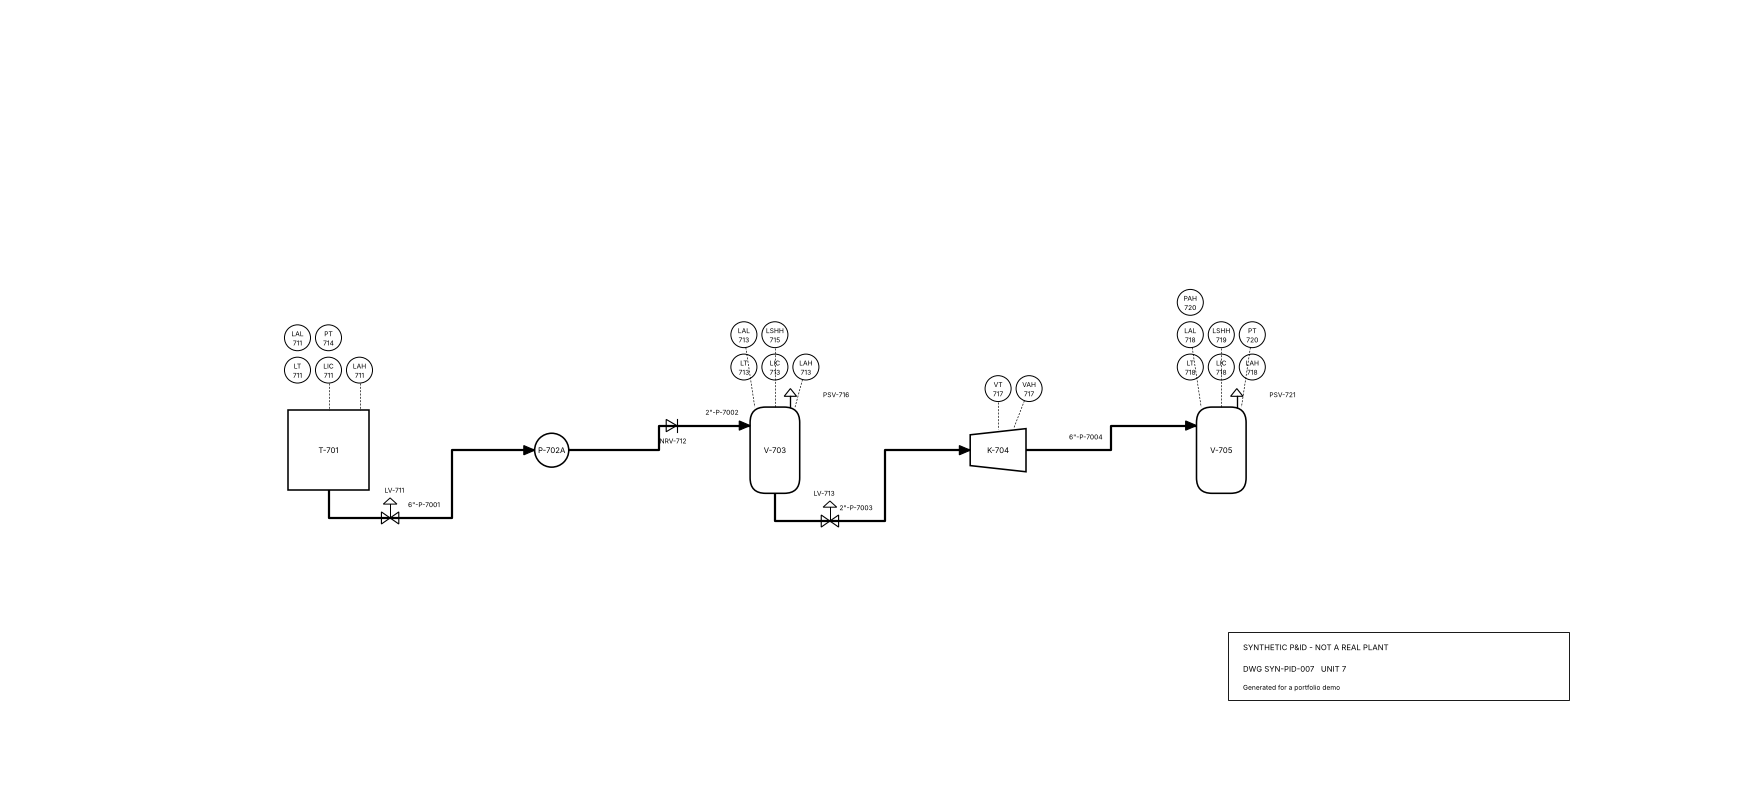

In [2]:
from src.data.load_data import load_data, load_truth
pdfs = load_data('drawings')
print(len(pdfs), 'standard drawings,', len(load_data('drawings_hard')), 'hard drawings')
from IPython.display import Image
Image('data/raw/drawings/SYN-PID-007.png', width=900)

## 2. Read it (features)
Thick polylines with an arrowhead are process lines; thin dashed lines are signal lines; bubbles carry ISA-5.1 function letters and a loop number.

In [3]:
from src.features.pid_reader import read_pid
m = read_pid('data/raw/drawings/SYN-PID-007.pdf')
print('equipment:', list(m.equipment))
pd.DataFrame([dict(line=k, start=l['from'], end=l['to'], valves=', '.join(l['valves'])) for k, l in m.lines.items()])

equipment: ['T-701', 'P-702A', 'V-703', 'K-704', 'V-705']


,line,start,end,valves
0,"6""-P-7001",T-701,P-702A,LV-711
1,"2""-P-7002",P-702A,V-703,NRV-712
2,"2""-P-7003",V-703,K-704,LV-713
3,"6""-P-7004",K-704,V-705,


In [4]:
pd.DataFrame([dict(tag=t, attached_to=v['attached_to'], method=v['method']) for t, v in m.instruments.items()]).head(12)

,tag,attached_to,method
0,LIC-711,T-701,signal line
1,LAH-711,T-701,signal line
2,LAH-713,V-703,signal line
3,LAL-713,V-703,signal line
4,LSHH-715,V-703,signal line
5,VT-717,K-704,signal line
6,VAH-717,K-704,signal line
7,LAL-718,V-705,signal line
8,LSHH-719,V-705,signal line
9,PT-720,V-705,signal line


## 3. Score the reading against the truth

In [5]:
from src.models.evaluate import score
pd.DataFrame(score(m, load_truth('SYN-PID-007'))).T

,true,found,correct,precision,recall
equipment,5.0,5.0,5.0,1.0,1.0
"lines (number, from, to)",4.0,4.0,4.0,1.0,1.0
valves on lines,3.0,3.0,3.0,1.0,1.0
relief valves,2.0,2.0,2.0,1.0,1.0
"instruments (tag, attached to)",19.0,19.0,19.0,1.0,1.0
instruments without signal line,9.0,9.0,9.0,1.0,1.0


## 4. Draft the HAZOP worksheet

In [6]:
from src.hazop.engine import Graph, draft_hazop
rows = draft_hazop(Graph.from_model(m))
print(len(rows), 'rows,', sum(bool(r.gap) for r in rows), 'with a gap for team review')
pd.DataFrame([r.as_dict() for r in rows]).head(6)

15 rows, 3 with a gap for team review


,node,equipment,parameter,guideword,deviation,causes,consequences,safeguards_on_drawing,gap_for_team_review
0,N01 T-701 (tank),T-701,Level,More,High level,LV-711 fails closed / LIC mis-set; downstream P-702A stopped,"tank overfill, loss of containment","LAH-711 (high-level alarm, operator response)",No independent high-high level trip found on drawing; team to decide if one is needed (LOPA).
1,N01 T-701 (tank),T-701,Level,Less,Low level,LV-711 fails open,"loss of suction to P-702A: cavitation, seal damage; gas blow-by through LV-711 to P-702A","LAL-711 (low-level alarm, operator response)",
2,N01 T-701 (tank),T-701,Pressure,More,High pressure,outlet blocked (LV-711 closed); external fire,"overpressure, possible loss of containment",none found on drawing,No relief valve found on drawing; confirm overpressure protection (may be on another sheet).
3,"N02 P-702A (pump) incl. inlet 6""-P-7001",P-702A,Flow,No,No / low flow,"low level in T-701; pump trip (power, mechanical)","pump runs dry or deadheaded: overheating, seal failure; loss of feed to V-703",LAL-711 (low level on suction vessel T-701),
4,"N02 P-702A (pump) incl. inlet 6""-P-7001",P-702A,Flow,Reverse,Reverse flow,pump stops while discharge side is at higher pressure,backflow into T-701; reverse rotation,NRV-712 (check valve),
5,"N02 P-702A (pump) incl. inlet 6""-P-7001",P-702A,Pressure,More,High discharge pressure,discharge blocked downstream,pump deadheaded; downstream overpressure if shut-off exceeds design,PSV-716 (relief on downstream equipment),


## 5. All 50 drawings (full pipeline)

In [7]:
from src import pipeline
res = pipeline.run()
for s in res:
    print(s); display(pd.DataFrame(res[s]['reading']).T); print(res[s]['hazop'])

drawings


,true,found,correct,precision,recall
equipment,134.0,134.0,134.0,1.0,1.0
"lines (number, from, to)",104.0,104.0,104.0,1.0,1.0
valves on lines,80.0,80.0,80.0,1.0,1.0
relief valves,52.0,52.0,52.0,1.0,1.0
"instruments (tag, attached to)",435.0,435.0,435.0,1.0,1.0
instruments without signal line,38.0,38.0,38.0,1.0,1.0


{'rows_true': 440, 'rows_read': 440, 'rows_in_both': 440, 'same_safeguards': 440, 'same_gap_call': 440, 'rows_identical': 440, 'gaps_true': 230}
drawings_hard


,true,found,correct,precision,recall
equipment,98.0,98.0,98.0,1.0000,1.0000
"lines (number, from, to)",78.0,78.0,78.0,1.0000,1.0000
valves on lines,64.0,64.0,64.0,1.0000,1.0000
relief valves,42.0,42.0,42.0,1.0000,1.0000
"instruments (tag, attached to)",323.0,276.0,271.0,0.9819,0.8390
instruments without signal line,229.0,202.0,197.0,0.9752,0.8603


{'rows_true': 319, 'rows_read': 319, 'rows_in_both': 319, 'same_safeguards': 295, 'same_gap_call': 312, 'rows_identical': 295, 'gaps_true': 163}


## Figures

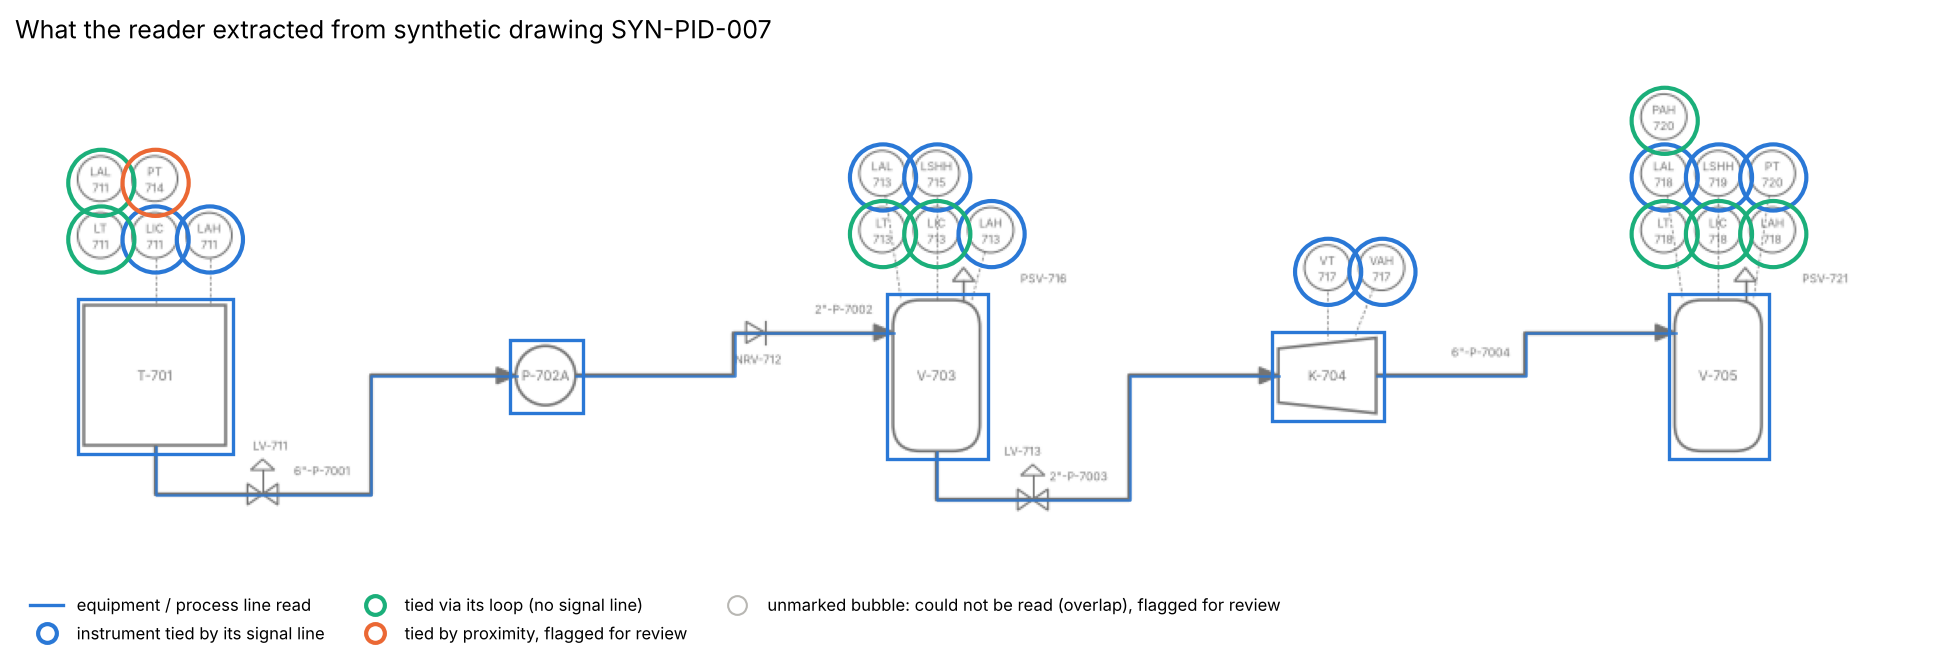

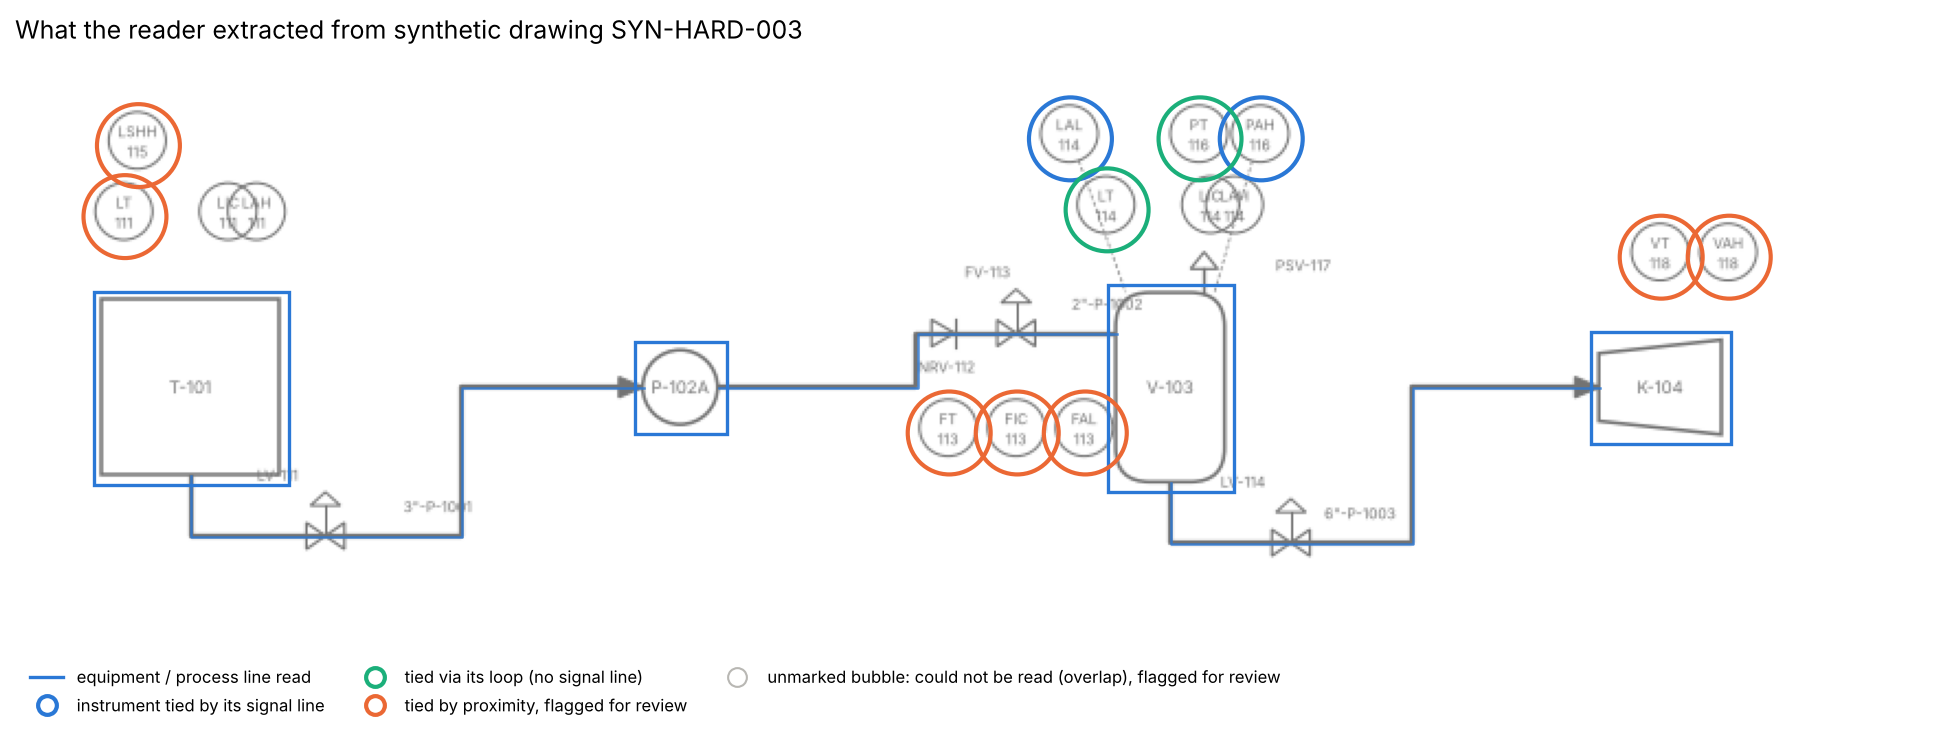

In [8]:
from src.utils import plots
plots.annotated('SYN-PID-007')
plots.annotated('SYN-HARD-003', folder='drawings_hard', out='annotated_pid_hard.png')
from IPython.display import display
display(Image('reports/figures/annotated_pid.png', width=900))
display(Image('reports/figures/annotated_pid_hard.png', width=900))

## Serve it
`uvicorn src.api.app:app --reload`, then open http://127.0.0.1:8000/docs and upload a PDF. The same call from Python:

In [9]:
from fastapi.testclient import TestClient
from src.api.app import app
with open('data/sample/SYN-PID-007.pdf', 'rb') as f:
    r = TestClient(app).post('/hazop', files={'file': ('SYN-PID-007.pdf', f, 'application/pdf')}).json()
print(len(r['hazop_rows']), 'HAZOP rows,', r['gaps'], 'gaps')
r['hazop_rows'][0]

15 HAZOP rows, 3 gaps


{'node': 'N01 T-701 (tank)',
 'equipment': 'T-701',
 'parameter': 'Level',
 'guideword': 'More',
 'deviation': 'High level',
 'causes': 'LV-711 fails closed / LIC mis-set; downstream P-702A stopped',
 'consequences': 'tank overfill, loss of containment',
 'safeguards_on_drawing': 'LAH-711 (high-level alarm, operator response)',
 'gap_for_team_review': 'No independent high-high level trip found on drawing; team to decide if one is needed (LOPA).'}